RANDOM FOREST CLASSIFICATION USING IRIS DATASET

Dataset Shape: (150, 6)

First 5 Rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Training Samples: 120
Testing Samples : 30

Random Forest Accuracy:
90.00%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   wei

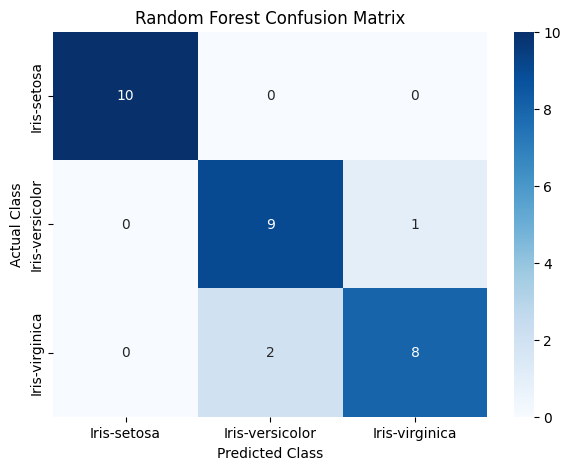

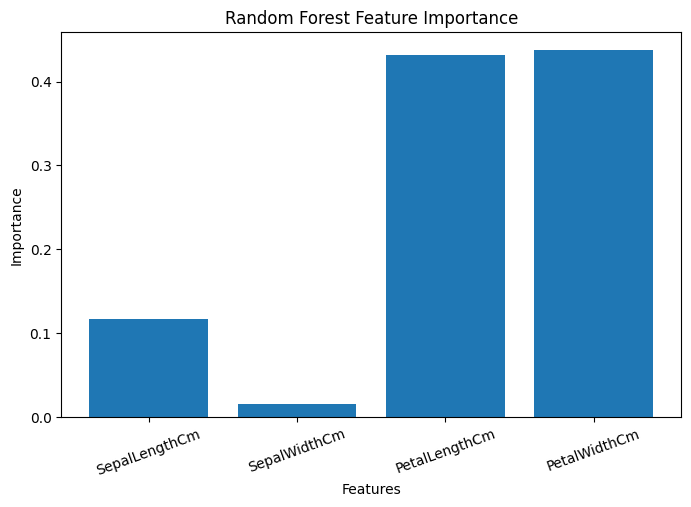


Feature Importance:
SepalLengthCm: 0.1163
SepalWidthCm: 0.0150
PetalLengthCm: 0.4315
PetalWidthCm: 0.4372

New Flower:
Sepal Length = 5.1
Sepal Width  = 3.5
Petal Length = 1.4
Petal Width  = 0.2

Predicted Species: Iris-setosa


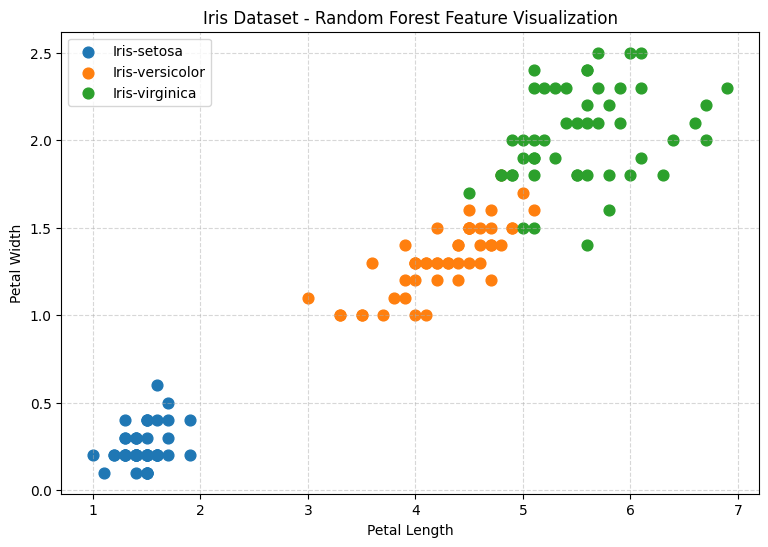


RANDOM FOREST PROJECT COMPLETED SUCCESSFULLY


In [10]:
# RANDOM FOREST CLASSIFICATION USING IRIS DATASET

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. LOAD IRIS DATASET
path = '/kaggle/input/datasets/uciml/iris/Iris.csv'
iris = pd.read_csv(path)

print('=' * 60)
print("RANDOM FOREST CLASSIFICATION USING IRIS DATASET")
print('=' * 60)

print("\nDataset Shape:", iris.shape)

print("\nFirst 5 Rows:")
print(iris.head())


# 2. SELECT FEATURES AND TARGET

features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = iris[features]

y = iris["Species"]


# 3. SPLIT DATA INTO TRAINING AND TESTING

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples :", len(X_test))


# 4. CREATE RANDOM FOREST MODEL

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


# 5. TRAIN THE MODEL

rf_model.fit(X_train, y_train)


# 6. MAKE PREDICTIONS

y_pred = rf_model.predict(X_test)


# 7. CALCULATE ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("\nRandom Forest Accuracy:")
print(f"{accuracy * 100:.2f}%")


# 8. CLASSIFICATION REPORT

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# 9. CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


# 10. FEATURE IMPORTANCE

importance = rf_model.feature_importances_

plt.figure(figsize=(8, 5))

plt.bar(features, importance)

plt.title("Random Forest Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.xticks(rotation=20)
plt.show()

print("\nFeature Importance:")

for feature, value in zip(features, importance):
    print(f"{feature}: {value:.4f}")


# 11. PREDICT A NEW FLOWER

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=features
)

prediction = rf_model.predict(new_flower)


print("\nNew Flower:")
print("Sepal Length = 5.1")
print("Sepal Width  = 3.5")
print("Petal Length = 1.4")
print("Petal Width  = 0.2")

print("\nPredicted Species:", prediction[0])


# 12. SIMPLE 2D VISUALIZATION

plt.figure(figsize=(9, 6))

for species in iris["Species"].unique():

    data = iris[iris["Species"] == species]

    plt.scatter(
        data["PetalLengthCm"],
        data["PetalWidthCm"],
        s=60,
        label=species
    )

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.title("Iris Dataset - Random Forest Feature Visualization")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()


# 13. PROJECT COMPLETED

print("\n" + "=" * 60)
print("RANDOM FOREST PROJECT COMPLETED SUCCESSFULLY")
print("=" * 60)